In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Exact Walsh validation of majority-block Fourier coefficients

This notebook independently validates the closed-form Walsh/Fourier coefficients of the binary majority observable by enumerating **every** Boolean input and computing the **complete** Walsh spectrum with a fast Walsh-Hadamard transform (FWHT).

We use the observable convention
\[
f_b(x)=\begin{cases}
+1,& |x|\le \lfloor b/2\rfloor,\\
-1,& |x|>\lfloor b/2\rfloor,
\end{cases}
\qquad
\widehat f_b(S)=2^{-b}\sum_x f_b(x)(-1)^{\sum_{i\in S}x_i}.
\]
For even blocks this is deterministic tie-breaking toward majority bit 0 (observable value (+1)).

For odd (b), the predicted coefficient at odd locality \(\ell\) is
\[
c_{b,\ell}=(-1)^{(\ell-1)/2}
\frac{\binom{(b-1)/2}{(\ell-1)/2}}{\binom{b-1}{\ell-1}}
\frac{\binom{b-1}{(b-1)/2}}{2^{b-1}},
\]
and all even-weight coefficients vanish. In particular,
\(c_{b,1}=\eta_b\) and \(c_{b,3}=-\eta_b/(b-2)\).

For even (b), deterministic ties give
\[
d_{b,\ell}=\begin{cases}
c_{b+1,\ell},&\ell\text{ odd},\\
c_{b+1,\ell+1},&\ell\text{ even},
\end{cases}
\]
so \(d_{b,0}=d_{b,1}=\binom{b}{b/2}/2^b\) and
\(d_{b,2}=d_{b,3}=-\eta_b/(b-1)\) whenever both sectors exist.

In [1]:
from __future__ import annotations

import json
import math
import platform
import sys
import time
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

QASP_ROOT = Path(".")
RESULTS_DIR = QASP_ROOT / "tests" / "results" / "majority_block_fourier_validation"
FIGURES_DIR = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SUMMARY_CSV = RESULTS_DIR / "majority_block_fourier_summary.csv"
SECTORS_CSV = RESULTS_DIR / "majority_block_fourier_sectors.csv"
ARCHIVE_NPZ = RESULTS_DIR / "majority_block_fourier_validation.npz"
METADATA_JSON = RESULTS_DIR / "metadata.json"
CAPTION_TXT = RESULTS_DIR / "figure_caption.txt"
FIGURE_PDF = FIGURES_DIR / "majority_block_fourier_validation.pdf"
FIGURE_PNG = FIGURES_DIR / "majority_block_fourier_validation.png"

ODD_BLOCKS = tuple(range(3, 20, 2))
EVEN_BLOCKS = tuple(range(2, 21, 2))
TOL = 1e-12

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 10,
    "legend.fontsize": 7.5,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

print(f"Results: {RESULTS_DIR}")
print(f"Figures: {FIGURES_DIR}")
print(f"Odd blocks: {ODD_BLOCKS}")
print(f"Even blocks: {EVEN_BLOCKS}")

Results: ./tests/results/majority_block_fourier_validation
Figures: <AUTHOR_HOME>/Desktop/research_papers/Trainability and Classical Simulability of Parameterized IQP-based Reinforcement Learning models /Figures
Odd blocks: (3, 5, 7, 9, 11, 13, 15, 17, 19)
Even blocks: (2, 4, 6, 8, 10, 12, 14, 16, 18, 20)


## Exact enumeration and analytical laws

The FWHT computes all \(2^b\) coefficients simultaneously. For each block size we compare every numerical coefficient with the coefficient predicted solely from its subset weight. We also test permutation symmetry by measuring the maximum within-weight deviation from the sector mean.

In [2]:
BYTE_POPCOUNT = np.unpackbits(
    np.arange(256, dtype=np.uint8)[:, None], axis=1
).sum(axis=1)


def popcount_u32(values: np.ndarray) -> np.ndarray:
    '''Vectorized Hamming weight for a contiguous uint32 array.'''
    words = np.ascontiguousarray(values, dtype=np.uint32)
    octets = words.view(np.uint8).reshape(-1, 4)
    return BYTE_POPCOUNT[octets].sum(axis=1).astype(np.int16)


def fwht(values: np.ndarray) -> np.ndarray:
    '''Normalized Walsh-Hadamard transform in the standard subset order.'''
    out = np.asarray(values, dtype=np.float64).copy()
    if out.ndim != 1 or out.size == 0 or out.size & (out.size - 1):
        raise ValueError("FWHT input length must be a positive power of two")
    width = 1
    while width < out.size:
        blocks = out.reshape(-1, 2 * width)
        left = blocks[:, :width].copy()
        right = blocks[:, width:].copy()
        blocks[:, :width] = left + right
        blocks[:, width:] = left - right
        width *= 2
    return out / out.size


def odd_coefficient(b: int, ell: int) -> float:
    '''Closed-form c_{b,ell} for odd b, including the vanishing sectors.'''
    if b % 2 != 1 or ell < 0 or ell > b:
        raise ValueError("b must be odd and 0 <= ell <= b")
    if ell % 2 == 0:
        return 0.0
    eta = math.comb(b - 1, (b - 1) // 2) / (2 ** (b - 1))
    ratio = (
        math.comb((b - 1) // 2, (ell - 1) // 2)
        / math.comb(b - 1, ell - 1)
    )
    return ((-1) ** ((ell - 1) // 2)) * ratio * eta


def even_coefficient(b: int, ell: int) -> float:
    '''Closed-form d_{b,ell} from the odd-(b+1) relation.'''
    if b % 2 != 0 or ell < 0 or ell > b:
        raise ValueError("b must be even and 0 <= ell <= b")
    return odd_coefficient(b + 1, ell if ell % 2 else ell + 1)


def package_version(name: str) -> str:
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


# Independent transform sanity check: delta at zero has a flat normalized spectrum.
delta = np.zeros(8)
delta[0] = 1.0
np.testing.assert_array_equal(fwht(delta), np.full(8, 1 / 8))
print("FWHT normalization sanity check passed.")

FWHT normalization sanity check passed.


In [3]:
summary_rows = []
sector_rows = []
started = time.perf_counter()

for b in sorted(ODD_BLOCKS + EVEN_BLOCKS):
    indices = np.arange(1 << b, dtype=np.uint32)
    input_weights = popcount_u32(indices)
    truth_table = np.where(input_weights <= b // 2, 1.0, -1.0)
    numerical = fwht(truth_table)
    subset_weights = input_weights  # integer masks use the same popcount map

    if b % 2:
        theory_by_weight = np.array([odd_coefficient(b, ell) for ell in range(b + 1)])
        parity = "odd"
    else:
        theory_by_weight = np.array([even_coefficient(b, ell) for ell in range(b + 1)])
        parity = "even"

    analytical = theory_by_weight[subset_weights]
    max_residual = float(np.max(np.abs(numerical - analytical)))
    max_sector_spread = 0.0
    numerical_by_weight = []

    for ell in range(b + 1):
        values = numerical[subset_weights == ell]
        sector_mean = float(values.mean())
        sector_spread = float(np.max(np.abs(values - sector_mean)))
        sector_residual = abs(sector_mean - theory_by_weight[ell])
        max_sector_spread = max(max_sector_spread, sector_spread)
        numerical_by_weight.append(sector_mean)
        sector_rows.append({
            "parity": parity,
            "b": b,
            "weight": ell,
            "multiplicity": math.comb(b, ell),
            "numerical_coefficient": sector_mean,
            "theory_coefficient": float(theory_by_weight[ell]),
            "absolute_residual": float(sector_residual),
            "within_sector_max_deviation": sector_spread,
        })

    numerical_by_weight = np.asarray(numerical_by_weight)
    if parity == "odd":
        eta = math.comb(b - 1, (b - 1) // 2) / (2 ** (b - 1))
        even_sector_max = float(np.max(np.abs(numerical_by_weight[::2])))
        np.testing.assert_allclose(numerical_by_weight[1], eta, rtol=0, atol=TOL)
        np.testing.assert_allclose(numerical_by_weight[3], -eta / (b - 2), rtol=0, atol=TOL)
        special = {
            "eta": eta,
            "coefficient_0_numerical": numerical_by_weight[0],
            "coefficient_0_theory": 0.0,
            "coefficient_1_numerical": numerical_by_weight[1],
            "coefficient_1_theory": eta,
            "coefficient_2_numerical": numerical_by_weight[2],
            "coefficient_2_theory": 0.0,
            "coefficient_3_numerical": numerical_by_weight[3],
            "coefficient_3_theory": -eta / (b - 2),
            "max_even_weight_abs": even_sector_max,
        }
    else:
        eta = math.comb(b, b // 2) / (2 ** b)
        np.testing.assert_allclose(numerical_by_weight[0], eta, rtol=0, atol=TOL)
        np.testing.assert_allclose(numerical_by_weight[1], eta, rtol=0, atol=TOL)
        np.testing.assert_allclose(numerical_by_weight[2], -eta / (b - 1), rtol=0, atol=TOL)
        if b >= 3:
            np.testing.assert_allclose(numerical_by_weight[3], -eta / (b - 1), rtol=0, atol=TOL)
        special = {
            "eta": eta,
            "coefficient_0_numerical": numerical_by_weight[0],
            "coefficient_0_theory": eta,
            "coefficient_1_numerical": numerical_by_weight[1],
            "coefficient_1_theory": eta,
            "coefficient_2_numerical": numerical_by_weight[2],
            "coefficient_2_theory": -eta / (b - 1),
            "coefficient_3_numerical": numerical_by_weight[3] if b >= 3 else np.nan,
            "coefficient_3_theory": -eta / (b - 1) if b >= 3 else np.nan,
            "max_even_weight_abs": np.nan,
        }

    assert max_residual <= TOL, (b, max_residual)
    assert max_sector_spread <= TOL, (b, max_sector_spread)
    summary_rows.append({
        "parity": parity,
        "b": b,
        "number_of_coefficients": 1 << b,
        "max_full_spectrum_abs_residual": max_residual,
        "max_within_weight_deviation": max_sector_spread,
        **special,
    })

elapsed = time.perf_counter() - started
summary = pd.DataFrame(summary_rows).sort_values("b").reset_index(drop=True)
sectors = pd.DataFrame(sector_rows).sort_values(["b", "weight"]).reset_index(drop=True)

assert len(summary) == 19
assert len(sectors) == 228
assert int(summary["number_of_coefficients"].sum()) == sum(1 << b for b in range(2, 21))

print(f"Validated {int(summary['number_of_coefficients'].sum()):,} coefficients in {elapsed:.3f} s.")
print(f"Maximum complete-spectrum residual: {summary['max_full_spectrum_abs_residual'].max():.3e}")
print(f"Maximum permutation-symmetry spread: {summary['max_within_weight_deviation'].max():.3e}")
display(summary)

Validated 2,097,148 coefficients in 0.227 s.
Maximum complete-spectrum residual: 1.084e-19
Maximum permutation-symmetry spread: 0.000e+00


,parity,b,number_of_coefficients,max_full_spectrum_abs_residual,max_within_weight_deviation,eta,coefficient_0_numerical,coefficient_0_theory,coefficient_1_numerical,coefficient_1_theory,coefficient_2_numerical,coefficient_2_theory,coefficient_3_numerical,coefficient_3_theory,max_even_weight_abs
0,even,2,4,0.000000e+00,0.0,0.500000,0.500000,0.500000,0.500000,0.500000,-0.500000,-0.500000,NaN,NaN,NaN
1,odd,3,8,0.000000e+00,0.0,0.500000,0.000000,0.000000,0.500000,0.500000,0.000000,0.000000,-0.500000,-0.500000,0.0
2,even,4,16,0.000000e+00,0.0,0.375000,0.375000,0.375000,0.375000,0.375000,-0.125000,-0.125000,-0.125000,-0.125000,NaN
3,odd,5,32,0.000000e+00,0.0,0.375000,0.000000,0.000000,0.375000,0.375000,0.000000,0.000000,-0.125000,-0.125000,0.0
4,even,6,64,0.000000e+00,0.0,0.312500,0.312500,0.312500,0.312500,0.312500,-0.062500,-0.062500,-0.062500,-0.062500,NaN
5,odd,7,128,0.000000e+00,0.0,0.312500,0.000000,0.000000,0.312500,0.312500,0.000000,0.000000,-0.062500,-0.062500,0.0
6,even,8,256,0.000000e+00,0.0,0.273438,0.273438,0.273438,0.273438,0.273438,-0.039062,-0.039062,-0.039062,-0.039062,NaN
7,odd,9,512,0.000000e+00,0.0,0.273438,0.000000,0.000000,0.273438,0.273438,0.000000,0.000000,-0.039062,-0.039062,0.0
8,even,10,1024,0.000000e+00,0.0,0.246094,0.246094,0.246094,0.246094,0.246094,-0.027344,-0.027344,-0.027344,-0.027344,NaN
9,odd,11,2048,0.000000e+00,0.0,0.246094,0.000000,0.000000,0.246094,0.246094,0.000000,0.000000,-0.027344,-0.027344,0.0


## Durable numerical outputs

The summary table records the complete-spectrum residual for every block size. The sector table records each distinct locality, its multiplicity, numerical coefficient, theoretical coefficient, residual, and within-sector symmetry check. The compressed NPZ deliberately stores sector-level rather than full (2^b)-length arrays; every individual coefficient is nevertheless compared above before reduction.

In [4]:
summary.to_csv(SUMMARY_CSV, index=False, float_format="%.17g")
sectors.to_csv(SECTORS_CSV, index=False, float_format="%.17g")

np.savez_compressed(
    ARCHIVE_NPZ,
    summary_b=summary["b"].to_numpy(dtype=np.int16),
    summary_parity=summary["parity"].to_numpy(dtype="U4"),
    summary_ncoeff=summary["number_of_coefficients"].to_numpy(dtype=np.int64),
    summary_max_residual=summary["max_full_spectrum_abs_residual"].to_numpy(),
    summary_max_symmetry_spread=summary["max_within_weight_deviation"].to_numpy(),
    sector_b=sectors["b"].to_numpy(dtype=np.int16),
    sector_weight=sectors["weight"].to_numpy(dtype=np.int16),
    sector_multiplicity=sectors["multiplicity"].to_numpy(dtype=np.int64),
    sector_numerical=sectors["numerical_coefficient"].to_numpy(),
    sector_theory=sectors["theory_coefficient"].to_numpy(),
    sector_residual=sectors["absolute_residual"].to_numpy(),
    sector_symmetry_spread=sectors["within_sector_max_deviation"].to_numpy(),
)

metadata = {
    "experiment": "exact majority-block Walsh/Fourier validation",
    "observable_convention": "+1 for Hamming weight <= floor(b/2), else -1",
    "even_tie_rule": "ties map to majority bit 0 / observable +1",
    "odd_blocks": list(ODD_BLOCKS),
    "even_blocks": list(EVEN_BLOCKS),
    "assertion_tolerance": TOL,
    "total_coefficients_checked": int(summary["number_of_coefficients"].sum()),
    "max_full_spectrum_abs_residual": float(summary["max_full_spectrum_abs_residual"].max()),
    "max_within_weight_deviation": float(summary["max_within_weight_deviation"].max()),
    "runtime_seconds": elapsed,
    "python": sys.version,
    "platform": platform.platform(),
    "package_versions": {
        "numpy": package_version("numpy"),
        "pandas": package_version("pandas"),
        "matplotlib": package_version("matplotlib"),
        "nbformat": package_version("nbformat"),
    },
    "files": {
        "summary_csv": str(SUMMARY_CSV),
        "sectors_csv": str(SECTORS_CSV),
        "archive_npz": str(ARCHIVE_NPZ),
        "figure_pdf": str(FIGURE_PDF),
        "figure_png": str(FIGURE_PNG),
    },
}
METADATA_JSON.write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

for path in (SUMMARY_CSV, SECTORS_CSV, ARCHIVE_NPZ, METADATA_JSON):
    print(f"Saved {path}")

Saved ./tests/results/majority_block_fourier_validation/majority_block_fourier_summary.csv
Saved ./tests/results/majority_block_fourier_validation/majority_block_fourier_sectors.csv
Saved ./tests/results/majority_block_fourier_validation/majority_block_fourier_validation.npz
Saved ./tests/results/majority_block_fourier_validation/metadata.json


## Publication figure

Markers are exact-enumeration/FWHT results, solid lines are the analytical laws, and the dashed gray curve is the amplitude-scale exponential reference \(2^{-b/2}\). The complete-spectrum residual remains reported in the caption and durable validation tables rather than as a separate subplot.

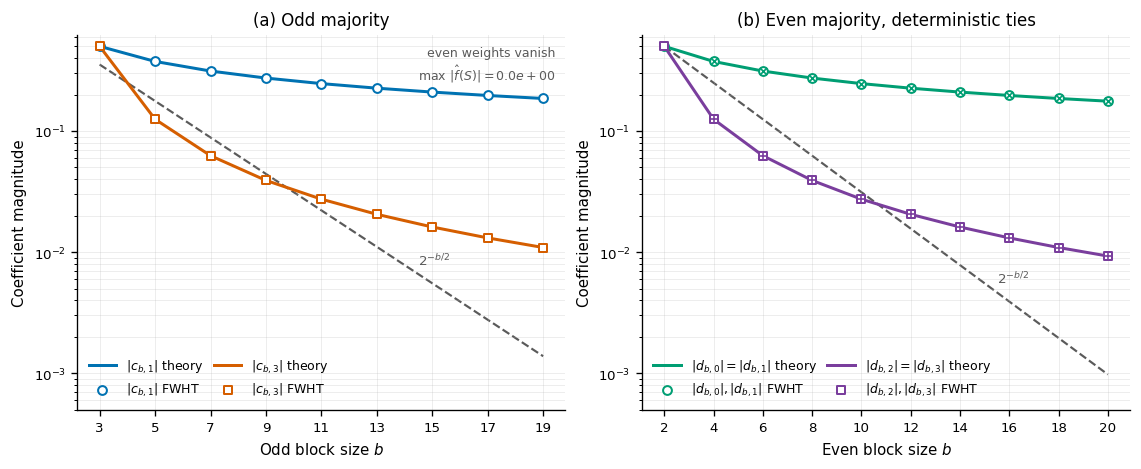

Saved <AUTHOR_HOME>/Desktop/research_papers/Trainability and Classical Simulability of Parameterized IQP-based Reinforcement Learning models /Figures/majority_block_fourier_validation.pdf
Saved <AUTHOR_HOME>/Desktop/research_papers/Trainability and Classical Simulability of Parameterized IQP-based Reinforcement Learning models /Figures/majority_block_fourier_validation.png
Saved ./tests/results/majority_block_fourier_validation/figure_caption.txt

Suggested caption:
Exact validation of majority-block Walsh coefficients. Markers show complete truth-table enumeration followed by a normalized fast Walsh-Hadamard transform; solid lines show the analytical coefficient laws and the dashed gray curve is the exponential reference 2^{-b/2}. (a) For odd blocks, the singleton and weight-three sectors follow c_{b,1}=eta_b and c_{b,3}=-eta_b/(b-2), while all even-weight coefficients vanish. (b) For even blocks with deterministic ties mapped to majority bit 0, d_{b,0}=d_{b,1} and d_{b,2}=d_{b,3}=-et

In [5]:
BLUE = "#0072B2"
VERMILLION = "#D55E00"
GREEN = "#009E73"
PURPLE = "#7A3E9D"
GRAY = "#5A5A5A"

odd = summary.loc[summary["parity"] == "odd"].sort_values("b")
even = summary.loc[summary["parity"] == "even"].sort_values("b")

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8), constrained_layout=True)

# (a) Odd blocks
ax = axes[0]
ax.plot(odd["b"], np.abs(odd["coefficient_1_theory"]), color=BLUE, lw=1.8, label=r"$|c_{b,1}|$ theory")
ax.scatter(odd["b"], np.abs(odd["coefficient_1_numerical"]), s=28, facecolors="white", edgecolors=BLUE, linewidths=1.2, zorder=3, label=r"$|c_{b,1}|$ FWHT")
ax.plot(odd["b"], np.abs(odd["coefficient_3_theory"]), color=VERMILLION, lw=1.8, label=r"$|c_{b,3}|$ theory")
ax.scatter(odd["b"], np.abs(odd["coefficient_3_numerical"]), s=28, marker="s", facecolors="white", edgecolors=VERMILLION, linewidths=1.2, zorder=3, label=r"$|c_{b,3}|$ FWHT")
odd_exp_reference = 2.0 ** (-odd["b"].to_numpy(dtype=float) / 2.0)
ax.plot(odd["b"], odd_exp_reference, color=GRAY, lw=1.3, ls="--", zorder=1)
ax.text(14.5, 2.0 ** (-14.5 / 2.0) * 1.12, r"$2^{-b/2}$", color=GRAY, fontsize=8, ha="left", va="bottom")
ax.set_yscale("log")
ax.set_ylim(5e-4, 6.2e-1)
ax.set_xticks(ODD_BLOCKS)
ax.set_xlabel("Odd block size $b$")
ax.set_ylabel("Coefficient magnitude")
ax.set_title("(a) Odd majority")
ax.grid(True, which="both", alpha=0.22, linewidth=0.6)
ax.legend(frameon=False, ncol=2, handlelength=2.2, columnspacing=0.8, loc="lower left")
odd_even_max = odd["max_even_weight_abs"].max()
ax.text(0.98, 0.97, "even weights vanish\n" + rf"max $|\hat f(S)|={odd_even_max:.1e}$", transform=ax.transAxes, ha="right", va="top", fontsize=7.5, color=GRAY)

# (b) Even blocks
ax = axes[1]
ax.plot(even["b"], np.abs(even["coefficient_0_theory"]), color=GREEN, lw=1.8, label=r"$|d_{b,0}|=|d_{b,1}|$ theory")
ax.scatter(even["b"], np.abs(even["coefficient_0_numerical"]), s=28, facecolors="white", edgecolors=GREEN, linewidths=1.2, zorder=3, label=r"$|d_{b,0}|,|d_{b,1}|$ FWHT")
ax.scatter(even["b"], np.abs(even["coefficient_1_numerical"]), s=18, marker="x", color=GREEN, linewidths=1.0, zorder=3, label="_nolegend_")
ax.plot(even["b"], np.abs(even["coefficient_2_theory"]), color=PURPLE, lw=1.8, label=r"$|d_{b,2}|=|d_{b,3}|$ theory")
ax.scatter(even["b"], np.abs(even["coefficient_2_numerical"]), s=28, marker="s", facecolors="white", edgecolors=PURPLE, linewidths=1.2, zorder=3, label=r"$|d_{b,2}|,|d_{b,3}|$ FWHT")
even_d3 = even.dropna(subset=["coefficient_3_numerical"])
ax.scatter(even_d3["b"], np.abs(even_d3["coefficient_3_numerical"]), s=18, marker="+", color=PURPLE, linewidths=1.0, zorder=3, label="_nolegend_")
even_exp_reference = 2.0 ** (-even["b"].to_numpy(dtype=float) / 2.0)
ax.plot(even["b"], even_exp_reference, color=GRAY, lw=1.3, ls="--", zorder=1)
ax.text(15.5, 2.0 ** (-15.5 / 2.0) * 1.12, r"$2^{-b/2}$", color=GRAY, fontsize=8, ha="left", va="bottom")
ax.set_yscale("log")
ax.set_ylim(5e-4, 6.2e-1)
ax.set_xticks(EVEN_BLOCKS)
ax.set_xlabel("Even block size $b$")
ax.set_ylabel("Coefficient magnitude")
ax.set_title("(b) Even majority, deterministic ties")
ax.grid(True, which="both", alpha=0.22, linewidth=0.6)
ax.legend(frameon=False, ncol=2, handlelength=2.2, columnspacing=0.8, loc="lower left")

fig.savefig(FIGURE_PDF, bbox_inches="tight")
fig.savefig(FIGURE_PNG, dpi=300, bbox_inches="tight")
plt.show()

caption = (
    "Exact validation of majority-block Walsh coefficients. "
    "Markers show complete truth-table enumeration followed by a normalized fast Walsh-Hadamard transform; "
    "solid lines show the analytical coefficient laws and the dashed gray curve is the exponential reference 2^{-b/2}. "
    "(a) For odd blocks, the singleton and weight-three sectors follow c_{b,1}=eta_b and "
    "c_{b,3}=-eta_b/(b-2), while all even-weight coefficients vanish. "
    "(b) For even blocks with deterministic ties mapped to majority bit 0, "
    "d_{b,0}=d_{b,1} and d_{b,2}=d_{b,3}=-eta_b/(b-1). "
    "Across all 2,097,148 enumerated coefficients, the maximum complete-spectrum discrepancy was "
    f"{summary['max_full_spectrum_abs_residual'].max():.2e}."
)
CAPTION_TXT.write_text(caption + "\n", encoding="utf-8")
print(f"Saved {FIGURE_PDF}")
print(f"Saved {FIGURE_PNG}")
print(f"Saved {CAPTION_TXT}")
print("\nSuggested caption:\n" + caption)

## Final validation checks

The assertions below re-read the durable tables, verify the requested block grids and row counts, and confirm that the saved summary still satisfies the complete-spectrum and permutation-symmetry tolerances.

In [6]:
saved_summary = pd.read_csv(SUMMARY_CSV)
saved_sectors = pd.read_csv(SECTORS_CSV)

assert saved_summary["b"].tolist() == list(range(2, 21))
assert saved_summary.loc[saved_summary["parity"] == "odd", "b"].tolist() == list(ODD_BLOCKS)
assert saved_summary.loc[saved_summary["parity"] == "even", "b"].tolist() == list(EVEN_BLOCKS)
assert len(saved_sectors) == 228
assert saved_summary["max_full_spectrum_abs_residual"].max() <= TOL
assert saved_summary["max_within_weight_deviation"].max() <= TOL
assert FIGURE_PDF.exists() and FIGURE_PDF.stat().st_size > 0
assert FIGURE_PNG.exists() and FIGURE_PNG.stat().st_size > 0

print("All final checks passed.")
print(f"Complete-spectrum maximum residual: {saved_summary['max_full_spectrum_abs_residual'].max():.17g}")
print(f"Permutation-symmetry maximum spread: {saved_summary['max_within_weight_deviation'].max():.17g}")
print(f"Notebook validated block sizes b = {saved_summary['b'].min()} through {saved_summary['b'].max()}.")

All final checks passed.
Complete-spectrum maximum residual: 1.0842021724855044e-19
Permutation-symmetry maximum spread: 0
Notebook validated block sizes b = 2 through 20.
